# V0 — ResNet50 on RGB CIFAR-10
Standalone RGB experiment using the existing 224×224 PNGs and train/test label manifests.
Train only randomly initialized RGB conv1 and fc; load the remaining ImageNet V1 weights
and freeze backbone parameters and BatchNorm statistics, matching the compressed protocol.
ImageNet input normalization is an explicit experimental difference from v2/v3 training-set statistics.
Metrics, training history and final test confusion matrices follow the compressed notebook.
Start a fresh kernel when changing configuration. Run initialization once; rerun the training
cell to add epochs. Test is held out from hyperparameter selection.

In [14]:
from pathlib import Path
import json
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

CHECKPOINT_NAME = "v0_20epochs_2026-10-16.pth"  # Filename in MODELS_DIR; None starts a new experiment.

# Local: run from the project root or notebooks/. On Colab mount Drive first
# and set PROJECT_ROOT to the folder containing data/ and output/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / "data" / "cifar-10_resized"
TRAIN_MANIFEST = PROJECT_ROOT / "output" / "manifest_train.json"
TEST_MANIFEST = PROJECT_ROOT / "output" / "manifest_test.json"
MODELS_DIR = PROJECT_ROOT / "output" / "models"
CHECKPOINT_TO_LOAD = MODELS_DIR / CHECKPOINT_NAME if CHECKPOINT_NAME else None
VERSION = "v0"
REPRESENTATION = "uncompressed-rgb-png-v0"
print("Device:",device, "\nDataset path:",DATA_ROOT)

Device: cuda 
Dataset path: C:\Users\Edward\Desktop\AARHUS\data\cifar-10_resized


In [15]:
# net parameters
BATCH_SIZE = 32
INITIAL_LR = 0.1
CHANNEL_MEAN = [0.485, 0.456, 0.406]
CHANNEL_STD = [0.229, 0.224, 0.225]
normalization_stats = dict(source="ImageNet", mean=CHANNEL_MEAN.copy(),
                           std=CHANNEL_STD.copy(), units="RGB float32 in [0,1]")

## Dataset and preprocessing
Reuse the manifests as label tables, mapping `.network.npz` names to `.png`.
Image paths are relative to the explicit RGB split directory, not the manifest directory.
No resize or crop: PNGs must already be RGB 224×224. Training alone uses horizontal flips.
ImageNet mean/std are a standard convention for the pretrained backbone, not universally
optimal RGB constants. Published CIFAR-10 statistics on 32×32 pixels need not describe
the resized dataset, particularly its standard deviation.


In [16]:
class RGBDataset(Dataset):
    def __init__(self, manifest_path, image_root, split, transform):
        self.manifest_path = Path(manifest_path)
        self.image_root = Path(image_root)
        self.transform = transform

        # The hash identifies the label table when resuming a checkpoint.
        raw = self.manifest_path.read_bytes()
        manifest = json.loads(raw)

        self.idx_to_class = {index: name for name, index in manifest['class_to_idx'].items()}

        # Existing manifests list NPZs; the RGB files have the same image IDs.
        self.samples = [
            dict(file=row['file'].removesuffix('.network.npz') + '.png', label=row['label'])
            for row in manifest['samples']
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        row = self.samples[index]
        with Image.open(self.image_root / row['file']) as image:
            image = self.transform(image)
        return image, torch.tensor(row['label'], dtype=torch.long)

train_transform = transforms.Compose([
    transforms.ToTensor(), transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
train_data = RGBDataset(TRAIN_MANIFEST, DATA_ROOT / 'train', 'train', train_transform)
test_data = RGBDataset(TEST_MANIFEST, DATA_ROOT / 'test', 'test', test_transform)
# Both splits must interpret class indices in the same way.
if train_data.idx_to_class != test_data.idx_to_class:
    raise ValueError("Train/test class mappings differ")

data_context = dict(image_size=[3, 224, 224], batch_size=BATCH_SIZE,
                    augmentation="horizontal_flip_p0.5", conv1="random_trainable",
                    backbone="ImageNet1K_V1_frozen", batchnorm="frozen",
                    normalization=normalization_stats)
print(f"Training: {len(train_data)}; test: {len(test_data)}")

Training: 50000; test: 10000


In [17]:
train_generator = torch.Generator().manual_seed(2)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_loader)} batches; test: {len(test_loader)} batches")

Train: 1563 batches; test: 313 batches


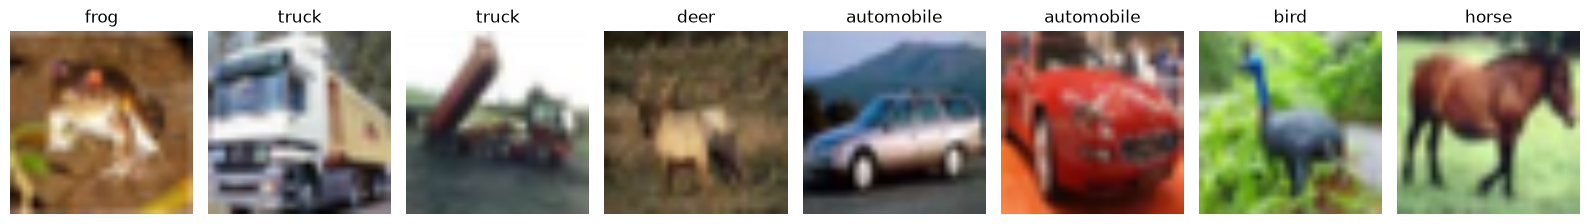

In [18]:
# Preview without consuming training-loader or augmentation RNG state.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(123)
    previews = [train_data[i] for i in range(8)]
images = torch.stack([item[0] for item in previews])
labels = torch.stack([item[1] for item in previews])
assert images.shape == (8, 3, 224, 224) and torch.isfinite(images).all()
mean = torch.tensor(CHANNEL_MEAN).view(3, 1, 1)
std = torch.tensor(CHANNEL_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, image, label in zip(axes, images, labels):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(train_data.idx_to_class[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## Model and frozen BatchNorm
BatchNorm normalizes intermediate features per channel. In training it uses batch
statistics and updates running mean/variance; in evaluation it uses the saved running
statistics. Its affine parameters (gamma/beta) are separately trainable.
Here requires_grad=False freezes gamma/beta, while the train() override keeps every
BatchNorm in eval mode to prevent running-statistic updates. Gradients still propagate
through the frozen backbone to conv1. This matches the compressed experiment.

In [19]:
import torchvision.models as models
import torch.nn as nn

class RGBResNet50(models.ResNet):
    def __init__(self, num_classes=10, pretrained=True):
        super().__init__(models.resnet.Bottleneck, [3, 4, 6, 3], num_classes=num_classes)
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        if pretrained:
            weights = models.ResNet50_Weights.IMAGENET1K_V1
            state = weights.get_state_dict(progress=True)
            state = {k: v for k, v in state.items()
                     if not (k.startswith("conv1.") or k.startswith("fc."))}
            self.load_state_dict(state, strict=False)
        nn.init.kaiming_normal_(self.conv1.weight, mode="fan_out", nonlinearity="relu")
        # Preserve the chosen experiment: train only the new conv1 and fc.
        for parameter in self.parameters():
            parameter.requires_grad = False
        for layer in (self.conv1, self.fc):
            for parameter in layer.parameters():
                parameter.requires_grad = True

    def train(self, mode=True):
        super().train(mode)
        # requires_grad=False does not freeze BatchNorm running statistics.
        # Keep the frozen backbone statistics fixed as well.
        for module in self.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
        return self
    # Inherit ResNet.forward: it already supports the replaced three-channel conv1.

In [ ]:
# Run once for a new experiment OR to restore a checkpoint.
# Do not rerun this cell when merely adding epochs in the current session.
import math


torch.manual_seed(42)

checkpoint = None 
if CHECKPOINT_TO_LOAD is not None:
    checkpoint = torch.load(CHECKPOINT_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint.get("version") != VERSION or checkpoint.get("representation") != REPRESENTATION:
        raise ValueError("Checkpoint version/representation differs (legacy checkpoints need explicit migration).")

model = RGBResNet50(num_classes=10, pretrained=checkpoint is None).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    (p for p in model.parameters() if p.requires_grad), lr=INITIAL_LR
)
history = []
test_metrics = None
if checkpoint is not None:
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    history = checkpoint["history"]
    if checkpoint["completed_epochs"] != len(history):
        raise ValueError("Checkpoint epoch count and history disagree.")
    test_metrics = checkpoint.get("test_metrics")

print("Completed epochs:", len(history))
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
if checkpoint is not None:
    torch.set_rng_state(checkpoint["torch_rng_state"])
    train_generator.set_state(checkpoint["loader_rng_state"])
    if torch.cuda.is_available() and checkpoint.get("cuda_rng_states"):
        if len(checkpoint["cuda_rng_states"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])
print("Model ready. Run the single training cell to add epochs.")

Completed epochs: 20
Total parameters: 23528522
Trainable parameters: 29898
Model ready. Run the single training cell to add epochs.


In [22]:
def train_step(model, data_loader, loss_fn, optimizer, device=device):
    model.to(device)
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        # CrossEntropyLoss uses the batch mean; weight it by actual batch size.
        batch_size = y.size(0)
        loss_sum += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += batch_size
    if count == 0:
        raise ValueError("Empty training loader")
    metrics = {"loss": loss_sum / count, "accuracy": 100.0 * correct / count}
    print(f"Train loss: {metrics['loss']:.5f} | Train accuracy: {metrics['accuracy']:.2f}%")
    return metrics


def test_step(model, data_loader, loss_fn, device=device):
    model.to(device)
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.inference_mode():
        for x, y in data_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss_sum += loss_fn(logits, y).item() * y.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            count += y.size(0)
    if count == 0:
        raise ValueError("Empty test loader")
    metrics = {"loss": loss_sum / count, "accuracy": 100.0 * correct / count}
    print(f"Test loss: {metrics['loss']:.5f} | Test accuracy: {metrics['accuracy']:.2f}%")
    return metrics

## Training
Each execution adds epochs. LR changes are explicit; resuming preserves the saved optimizer LR.

In [19]:
NEW_LR = 0.001  # Optional positive value; None preserves optimizer LR.
if NEW_LR is not None:
    if not math.isfinite(NEW_LR) or NEW_LR <= 0:
        raise ValueError("NEW_LR must be finite and positive")
    for group in optimizer.param_groups:
        group['lr'] = NEW_LR
print('Current learning rates:', [group['lr'] for group in optimizer.param_groups])

Current learning rates: [0.001]


In [20]:
# SINGLE TRAINING LOOP: every execution adds ADDITIONAL_EPOCHS.
# Keep the existing model, optimizer and history; no reset here.
from tqdm.auto import tqdm
from timeit import default_timer as timer

ADDITIONAL_EPOCHS = 5

start_epoch = len(history)
end_epoch = start_epoch + ADDITIONAL_EPOCHS
start_time = timer()
test_metrics = None  # Any previous test result refers to older weights.
for epoch in tqdm(range(start_epoch + 1, end_epoch + 1)):
    print(f"\nEpoch {epoch}/{end_epoch}")
    epoch_start = timer()
    metrics = train_step(model, train_loader, loss_fn, optimizer, device)
    epoch_seconds = timer() - epoch_start
    history.append({"epoch": epoch, "loss": float(metrics["loss"]),
                    "accuracy": float(metrics["accuracy"]),
                    "lr": float(optimizer.param_groups[0]["lr"]),
                    "training_seconds": epoch_seconds,
                    "training_device": str(device)})
print(f"Completed epochs: {len(history)}; elapsed: {timer() - start_time:.1f}s")
# Fixed learning rate: the held-out test does not guide training.

  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 16/20
Train loss: 0.31587 | Train accuracy: 89.15%

Epoch 17/20
Train loss: 0.31202 | Train accuracy: 89.35%

Epoch 18/20
Train loss: 0.30877 | Train accuracy: 89.42%

Epoch 19/20
Train loss: 0.30969 | Train accuracy: 89.42%

Epoch 20/20
Train loss: 0.30919 | Train accuracy: 89.40%
Completed epochs: 20; elapsed: 1776.5s


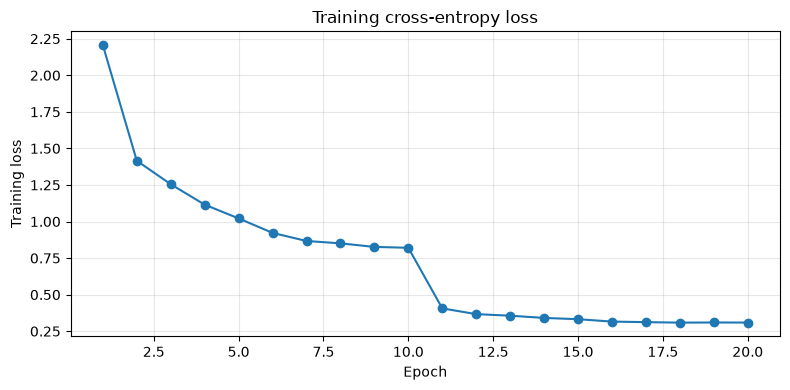

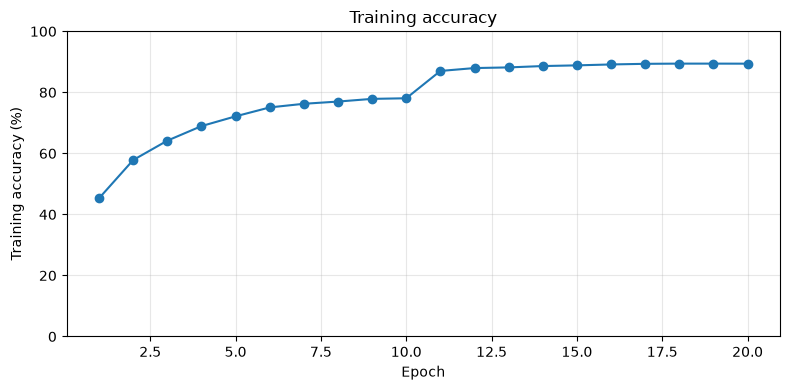

In [21]:
# Learning curves over ALL completed epochs, including restored history.
if not history:
    raise ValueError("Train or load a checkpoint with history first.")
epoch_numbers = [entry["epoch"] for entry in history]
fig_loss, ax_loss = plt.subplots(figsize=(8, 4))
ax_loss.plot(epoch_numbers, [entry["loss"] for entry in history], marker="o")
ax_loss.set(xlabel="Epoch", ylabel="Training loss", title="Training cross-entropy loss")
ax_loss.grid(alpha=0.3)
fig_loss.tight_layout()
plt.show()

fig_accuracy, ax_accuracy = plt.subplots(figsize=(8, 4))
ax_accuracy.plot(epoch_numbers, [entry["accuracy"] for entry in history], marker="o")
ax_accuracy.set(xlabel="Epoch", ylabel="Training accuracy (%)",
                title="Training accuracy", ylim=(0, 100))
ax_accuracy.grid(alpha=0.3)
fig_accuracy.tight_layout()
plt.show()

## Final held-out test evaluation
Same loss, accuracy and confusion-matrix definitions as the compressed experiment.

Test loss: 0.37580; accuracy: 87.74%


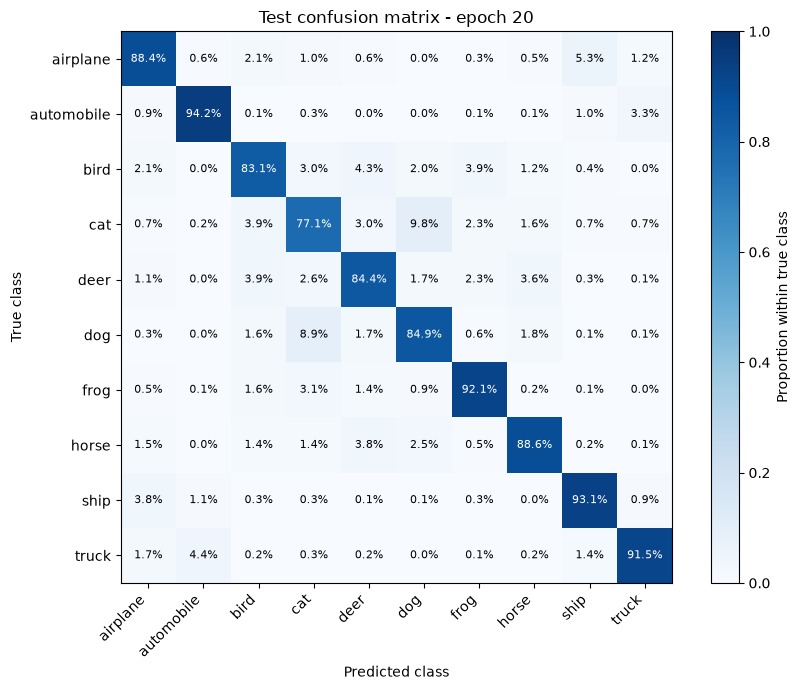

In [22]:
# Evaluate the current weights on test; do not use this to tune hyperparameters.
# Rows = true classes, columns = predicted classes. Each supported row sums to 1.
import numpy as np

num_classes = 10
class_names = [test_data.idx_to_class[i] for i in range(num_classes)]
confusion_counts = np.zeros((num_classes, num_classes), dtype=np.int64)
loss_sum, sample_count = 0.0, 0
model.eval()
with torch.inference_mode():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        predictions = logits.argmax(dim=1)
        loss_sum += loss_fn(logits, y).item() * y.size(0)
        sample_count += y.size(0)
        pairs = (y * num_classes + predictions).cpu().numpy()
        confusion_counts += np.bincount(pairs, minlength=num_classes**2).reshape(num_classes, num_classes)
if sample_count == 0:
    raise ValueError("Empty test loader")
support = confusion_counts.sum(axis=1, keepdims=True)
confusion_proportions = np.divide(confusion_counts, support,
    out=np.zeros_like(confusion_counts, dtype=np.float64), where=support != 0)
test_metrics = {"epoch": len(history), "loss": loss_sum / sample_count,
    "accuracy": 100.0 * float(np.trace(confusion_counts)) / sample_count,
    "confusion_counts": confusion_counts.tolist(),
    "confusion_proportions": confusion_proportions.tolist()}
print(f"Test loss: {test_metrics['loss']:.5f}; accuracy: {test_metrics['accuracy']:.2f}%")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion_proportions, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proportion within true class")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix - epoch {len(history)}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(num_classes):
    for j in range(num_classes):
        value = confusion_proportions[i, j]
        label = f"{value:.1%}" if support[i, 0] else "N/A"
        ax.text(j, i, label, ha="center", va="center",
                color="white" if value > 0.5 else "black", fontsize=8)
fig.tight_layout()
plt.show()
# Diagonal = recall per class. N/A means that class is absent from this split.

## Checkpoint
Contains optimizer, metrics, history, protocol and RNG states. Save after evaluation to include test results.

In [ ]:
# Save to the configured persistent model directory after any additional training.
from datetime import datetime
from zoneinfo import ZoneInfo

MODELS_DIR.mkdir(parents=True, exist_ok=True)
date = datetime.now(ZoneInfo("Europe/Rome")).strftime("%Y-%m-%d")
MODEL_SAVE_PATH = MODELS_DIR / f"v0_{len(history)}epochs_{date}.pth"

def summarize_training_time(entries):
    measured = [float(entry["training_seconds"]) for entry in entries if "training_seconds" in entry]
    return {
        "unit": "seconds",
        "total_seconds": sum(measured),
        "timed_epochs": len(measured),
        "scope": "Completed epochs: train_step wall time including data loading, preprocessing, transfers and optimizer updates; excludes setup, checks, test, plots, saving, pauses and interrupted epochs.",
    }

training_time = summarize_training_time(history)
checkpoint_to_save = {
    "schema": "resnet-rgb-checkpoint-v0",
    "scale": "None",
    "version": VERSION,
    "representation": REPRESENTATION, 
    "data_context": data_context,  
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(), "num_classes": 10,
    "completed_epochs": len(history), "history": history,
    "training_time": training_time,
    "normalization": normalization_stats,
    "idx_to_class": train_data.idx_to_class,
    "train_manifest": str(TRAIN_MANIFEST), 
    "test_manifest": str(TEST_MANIFEST),
    "test_metrics": test_metrics,
    "torch_rng_state": torch.get_rng_state(),
    "loader_rng_state": train_generator.get_state(),
    "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
}
# Exclusive creation prevents accidentally replacing a previous checkpoint.

with MODEL_SAVE_PATH.open("xb") as destination:
    torch.save(checkpoint_to_save, destination)

print(f"Saved {len(history)} completed epochs to {MODEL_SAVE_PATH}")

Saved 20 completed epochs to C:\Users\Edward\Desktop\AARHUS\output\models\v0_20epochs_2026-10-16_2.pth


To resume: start a fresh kernel, set CHECKPOINT_NAME in configuration, then run
through model initialization. Run the training cell to add epochs or evaluate directly.
Do not rerun initialization merely to add epochs. Compare matching epoch counts and LR
schedules on the same hardware. Training seconds include loading, transforms and updates.
Manifest hashes check label-table identity, not image contents; do not replace PNGs during a run.

References: [ResNet50 normalization](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet50.html)
and [BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).